# 03 — Analisis Univariat
| | |
|---|---|
| **Nama tim** | Kelompok Alpha |
| **Anggota** | Alfandi Panca Saputra (0110225026) <br>Muhammad Sultan Ridho (0110225099)<br>Dzakwan Abdur Rasyid (0110225036)<br>Mumtaz Abdurrahman (0110225164) |
| **Topik proyek** | Eksplorasi Data Penjualan Bakery |
| **Tanggal** | 9 November 2026 |


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from pathlib import Path

PROCESSED = Path('/content/drive/MyDrive/Praktikum EDA/Proyek Tim/Data/processed')
df = pd.read_csv(PROCESSED / 'bakery_bersih.csv')

df['datetime'] = pd.to_datetime(df['date'] + ' ' + df['time'])

DATA = '#0E7490'; SOROT = '#C2410C'

print(f'{df.shape[0]} baris x {df.shape[1]} kolom')
display(df.head())

232795 baris x 9 kolom


,date,time,ticket_number,article,Quantity,unit_price,total_bayar,bulan,datetime
0,2021-01-02,08:38,150040,Baguette,1.0,0.90,0.90,2021-01,2021-01-02 08:38:00
1,2021-01-02,08:38,150040,Pain Au Chocolat,3.0,1.20,3.60,2021-01,2021-01-02 08:38:00
2,2021-01-02,09:14,150041,Pain Au Chocolat,2.0,1.20,2.40,2021-01,2021-01-02 09:14:00
3,2021-01-02,09:14,150041,Pain,1.0,1.15,1.15,2021-01,2021-01-02 09:14:00
4,2021-01-02,09:25,150042,Traditional Baguette,5.0,1.20,6.00,2021-01,2021-01-02 09:25:00


In [10]:
print("Daftar kolom di DataFrame:", df.columns.tolist())

NUMERIK = [col for col in ['Quantity', 'total_sales'] if col in df.columns]
if NUMERIK:
    print("\n", df[NUMERIK].describe().T.round(2).to_string())
else:
    print("Kolom numerik tidak ditemukan.")

Daftar kolom di DataFrame: ['date', 'time', 'ticket_number', 'article', 'Quantity', 'unit_price', 'total_bayar', 'bulan', 'datetime']

              count  mean  std  min  25%  50%  75%    max
Quantity  231511.0  1.56  1.2  1.0  1.0  1.0  2.0  200.0


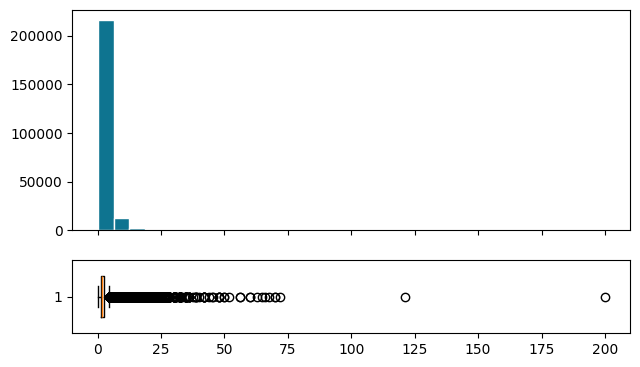

In [12]:
def potret(kolom, satuan=''):
    d = df[kolom].dropna()
    q1, q3 = d.quantile([.25, .75]); iqr = q3 - q1
    bawah, atas = q1 - 1.5*iqr, q3 + 1.5*iqr
    fig, ax = plt.subplots(2, 1, figsize=(7.2, 4.2), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
    ax[0].hist(d, bins=32, color=DATA, edgecolor='white')
    ax[1].boxplot(d, vert=False, widths=.55)
    plt.show()

potret('total_bayar', '€')

**Tafsiran:** Distribusi `total_sales` sangat menjulur ke kanan (right-skewed). Mayoritas transaksi berada di bawah 5 Euro, menandakan sebagian besar pembelian di bakery adalah transaksi skala kecil (misalnya hanya 1 baguette atau roti).

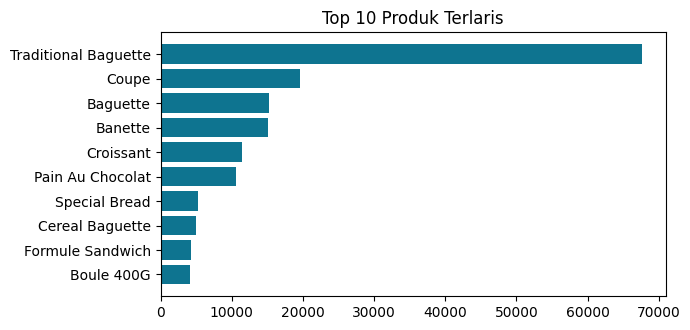

In [13]:
KATEGORIKAL = ['article']
vc = df['article'].value_counts().head(10)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(vc.index[::-1], vc.values[::-1], color=DATA)
ax.set_title('Top 10 Produk Terlaris')
plt.tight_layout(); plt.show()